In [1]:
import pandas as pd

chemin = "../data/raw/task_usage/part-00000-of-00500.csv.gz"
df = pd.read_csv(chemin, header=None, nrows=100000)

print(df.shape)
df.head()

(100000, 20)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,600000000,900000000,3418309,0,4155527081,0.001562,0.06787,0.07568,0.001156,0.001503,0.06787,0.000003,0.000187,0.039670,0.000357,2.445,0.007243,0,1,0.0
1,600000000,900000000,3418309,1,329150663,0.001568,0.06787,0.07556,0.000320,0.000700,0.06787,0.000006,0.000188,0.033020,0.000929,2.100,0.005791,0,1,0.0
2,600000000,900000000,3418314,0,3938719206,0.000307,0.08044,0.09521,0.000282,0.000670,0.08044,0.000005,0.000184,0.023770,0.000786,5.588,0.020800,0,1,0.0
3,600000000,900000000,3418314,1,351618647,0.000300,0.08044,0.09521,0.000537,0.000870,0.08044,0.000010,0.000183,0.007919,0.002285,5.198,0.020380,0,1,0.0
4,600000000,900000000,3418319,0,431052910,0.000461,0.07715,0.08740,0.000625,0.000852,0.07715,0.000002,0.000204,0.005112,0.000215,2.937,0.009449,0,1,0.0


In [2]:
df = df[[0, 5, 6]]
df.columns = ["start_time", "cpu", "mem"]

print(df.describe())
print("Valeurs manquantes :\n", df.isna().sum())
print("Fenêtres distinctes :", df["start_time"].nunique())

        start_time            cpu            mem
count     100000.0  100000.000000  100000.000000
mean   600000000.0       0.014663       0.020789
std            0.0       0.034942       0.038780
min    600000000.0       0.000000       0.000000
25%    600000000.0       0.000190       0.000594
50%    600000000.0       0.000224       0.001972
75%    600000000.0       0.013050       0.023530
max    600000000.0       0.479000       0.752000
Valeurs manquantes :
 start_time    0
cpu           0
mem           0
dtype: int64
Fenêtres distinctes : 1


In [3]:
df = pd.read_csv(chemin, header=None, usecols=[0, 5, 6])
df.columns = ["start_time", "cpu", "mem"]

print("Lignes :", len(df))
print("Mémoire (Mo) :", round(df.memory_usage().sum() / 1e6, 1))
print("Valeurs manquantes :\n", df.isna().sum())

df["window"] = df["start_time"] // (300 * 1_000_000)
print(df["window"].value_counts().sort_index())

Lignes : 2520773
Mémoire (Mo) : 60.5
Valeurs manquantes :
 start_time    0
cpu           0
mem           0
dtype: int64
window
2     144348
3     144222
4     153278
5     156127
6     145568
7     166103
8     164042
9     156897
10    147470
11    143087
12    139691
13    144791
14    146128
15    141431
16    146267
17    144707
18    136616
Name: count, dtype: int64


In [4]:
# Agrégation du fichier 0
agg0 = df.groupby("window")[["cpu", "mem"]].sum()

# Lecture du fichier 1
chemin1 = "../data/raw/task_usage/part-00001-of-00500.csv.gz"
df1 = pd.read_csv(chemin1, header=None, usecols=[0, 5, 6])
df1.columns = ["start_time", "cpu", "mem"]
df1["window"] = df1["start_time"] // (300 * 1_000_000)
agg1 = df1.groupby("window")[["cpu", "mem"]].sum()

print("Fichier 0 :", agg0.index.min(), "->", agg0.index.max())
print("Fichier 1 :", agg1.index.min(), "->", agg1.index.max())
print(agg0.tail(3))
print(agg1.head(3))

Fichier 0 : 2 -> 18
Fichier 1 : 18 -> 35
                cpu          mem
window                          
16      2396.914593  2869.725015
17      2194.592371  2784.944757
18      2047.569593  2704.336957
                cpu          mem
window                          
18        30.806027    15.332703
19      2127.673929  2702.474287
20      2125.289669  2706.393561


Nombre de fenêtres : 34
                cpu          mem
window                          
17      2194.592371  2784.944757
18      2078.375620  2719.669660
19      2127.673929  2702.474287


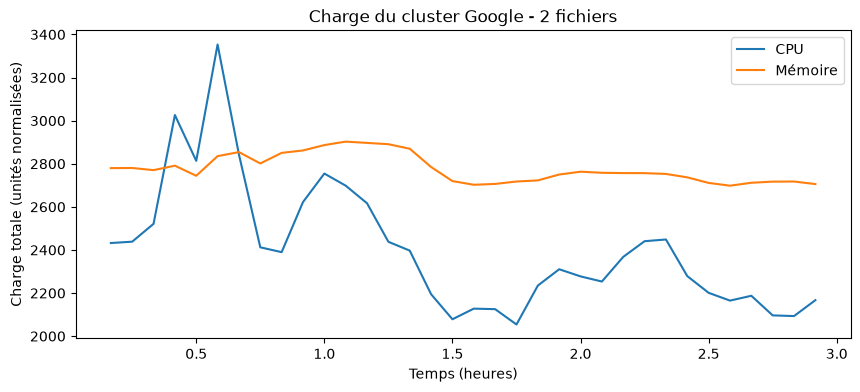

In [5]:
import matplotlib.pyplot as plt

charge = pd.concat([agg0, agg1]).groupby(level=0).sum()

print("Nombre de fenêtres :", len(charge))
print(charge.loc[17:19])

plt.figure(figsize=(10, 4))
plt.plot(charge.index * 5 / 60, charge["cpu"], label="CPU")
plt.plot(charge.index * 5 / 60, charge["mem"], label="Mémoire")
plt.xlabel("Temps (heures)")
plt.ylabel("Charge totale (unités normalisées)")
plt.legend()
plt.title("Charge du cluster Google - 2 fichiers")
plt.show()